<a href="https://colab.research.google.com/github/mariamhamdi917-stack/ML_projects/blob/main/Adult_Census_Income.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import sklearn as sk
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
df= pd.read_csv("/content/Adult Census Income.csv")

In [ ]:
df.head()

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


In [ ]:
print(df.shape)

(32561, 15)


In [ ]:
print(df.isnull().sum())

age               0
workclass         0
fnlwgt            0
education         0
education.num     0
marital.status    0
occupation        0
relationship      0
race              0
sex               0
capital.gain      0
capital.loss      0
hours.per.week    0
native.country    0
income            0
dtype: int64


In [ ]:
for col in df.select_dtypes(include=['object']).columns:
    count = (df[col] == '?').sum()
    if count > 0:
        print(f"{col}: {count}")

workclass: 1836
occupation: 1843
native.country: 583


In [ ]:
df.replace('?', np.nan, inplace=True)
df.drop_duplicates(inplace=True)

print(df.shape)
print(df.isnull().sum())

(32537, 15)
age                  0
workclass         1836
fnlwgt               0
education            0
education.num        0
marital.status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital.gain         0
capital.loss         0
hours.per.week       0
native.country     582
income               0
dtype: int64


In [ ]:
# replace
df['native.country'].fillna(df['native.country'].mode()[0], inplace=True)

/tmp/ipykernel_1471/1892400779.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['native.country'].fillna(df['native.country'].mode()[0], inplace=True)


In [ ]:
#delete rows
df.dropna(subset=['workclass', 'occupation'], inplace=True)

print( df.shape)
print(df.isnull().sum())

(30694, 15)
age               0
workclass         0
fnlwgt            0
education         0
education.num     0
marital.status    0
occupation        0
relationship      0
race              0
sex               0
capital.gain      0
capital.loss      0
hours.per.week    0
native.country    0
income            0
dtype: int64


In [ ]:
print( df.duplicated().sum())

0


**visualization**

/tmp/ipykernel_1471/1292763554.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='income', data=df, palette='viridis')


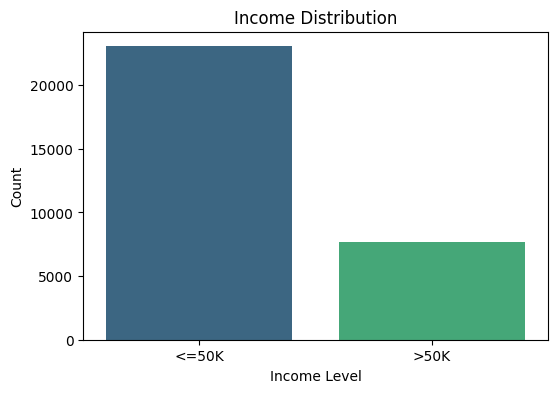

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
sns.countplot(x='income', data=df, palette='viridis')
plt.title('Income Distribution')
plt.xlabel('Income Level')
plt.ylabel('Count')
plt.show()

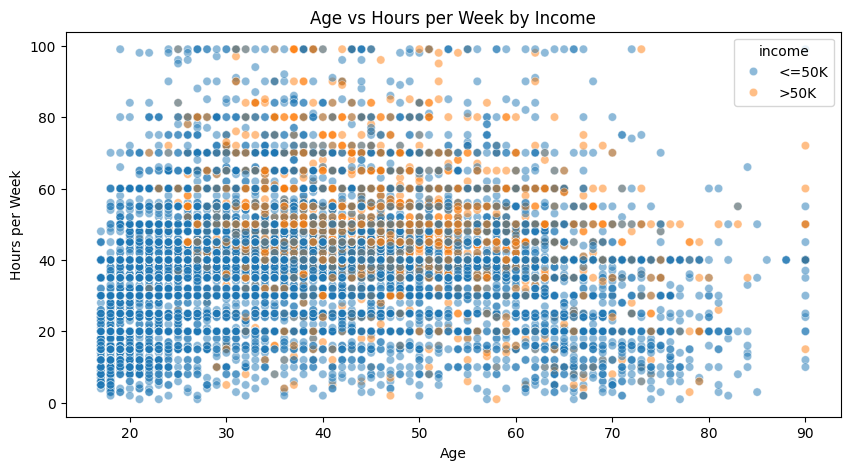

In [ ]:
plt.figure(figsize=(10, 5))
sns.scatterplot(x='age', y='hours.per.week', hue='income', data=df, alpha=0.5)
plt.title('Age vs Hours per Week by Income')
plt.xlabel('Age')
plt.ylabel('Hours per Week')
plt.show()

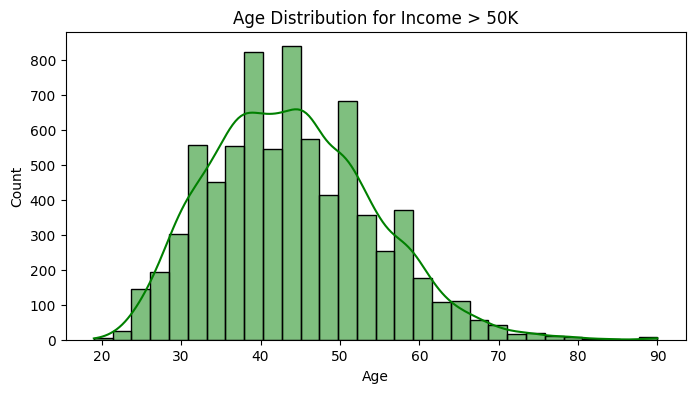

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

#>>50
df_high_income = df[df['income'] == '>50K']

# dis age  with>50
plt.figure(figsize=(8, 4))
sns.histplot(df_high_income['age'], bins=30, kde=True, color='green')
plt.title('Age Distribution for Income > 50K')
plt.xlabel('Age')
plt.ylabel('Count')
plt.show()

In [ ]:
#label encoding
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()

df['income'] = le.fit_transform(df['income'])

df['sex'] = le.fit_transform(df['sex'])

In [ ]:
# onehot encoding
categorical_cols = ['workclass', 'marital.status', 'occupation', 'relationship', 'race', 'native.country', 'education']
df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

In [ ]:
# split x , y
X = df_encoded.drop(columns=['income'])
y = df_encoded['income']

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (30694, 96)
y shape: (30694,)


In [ ]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)



In [ ]:

print("X_train :", X_train.shape)
print("X_test :", X_test.shape)
print("y_train :", y_train.shape)
print("y_test :", y_test.shape)

X_train : (24555, 96)
X_test : (6139, 96)
y_train : (24555,)
y_test : (6139,)


In [ ]:
#minmax scalling
from sklearn.preprocessing import MinMaxScaler

numerical_cols = ['age', 'fnlwgt', 'education.num', 'capital.gain', 'capital.loss', 'hours.per.week']

scaler = MinMaxScaler()

X_train[numerical_cols] = scaler.fit_transform(X_train[numerical_cols])
X_test[numerical_cols] = scaler.transform(X_test[numerical_cols])

In [ ]:
#log class
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(random_state=42, max_iter=1000, class_weight='balanced')
model.fit(X_train, y_train)


LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

In [ ]:
#log matrix
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

y_pred = model.predict(X_test)

print(f"Accuracy: {accuracy_score(y_test, y_pred):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.8024

Classification Report:
              precision    recall  f1-score   support

           0       0.94      0.79      0.86      4609
           1       0.57      0.85      0.68      1530

    accuracy                           0.80      6139
   macro avg       0.75      0.82      0.77      6139
weighted avg       0.85      0.80      0.81      6139


Confusion Matrix:
[[3631  978]
 [ 235 1295]]


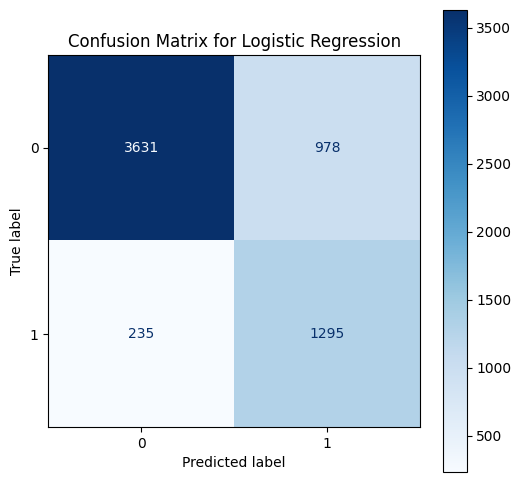

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)

fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(cmap=plt.cm.Blues, ax=ax, values_format='d')
plt.title("Confusion Matrix for Logistic Regression")
plt.show()

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train, y_train)
y_pred_knn = knn_model.predict(X_test)

print("KNN Accuracy:", accuracy_score(y_test, y_pred_knn))
print("\nClassification Report:\n", classification_report(y_test, y_pred_knn))

KNN Accuracy: 0.8188630070043981

Classification Report:
               precision    recall  f1-score   support

           0       0.87      0.90      0.88      4609
           1       0.65      0.58      0.61      1530

    accuracy                           0.82      6139
   macro avg       0.76      0.74      0.75      6139
weighted avg       0.81      0.82      0.82      6139



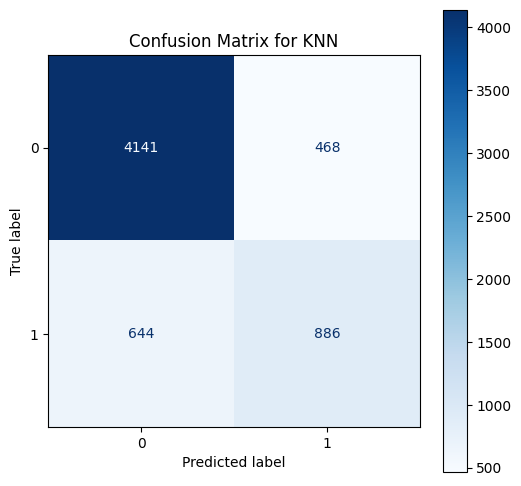

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_knn = confusion_matrix(y_test, y_pred_knn)
disp_knn = ConfusionMatrixDisplay(confusion_matrix=cm_knn, display_labels=knn_model.classes_)

fig, ax = plt.subplots(figsize=(6, 6))
disp_knn.plot(cmap=plt.cm.Blues, ax=ax, values_format='d')
plt.title("Confusion Matrix for KNN")
plt.show()

In [ ]:
from sklearn.naive_bayes import GaussianNB

naive_bayes_model = GaussianNB()
naive_bayes_model.fit(X_train, y_train)
y_pred_nb = naive_bayes_model.predict(X_test)
print("Naive Bayes Accuracy:", accuracy_score(y_test, y_pred_nb))

Naive Bayes Accuracy: 0.5238638214692947


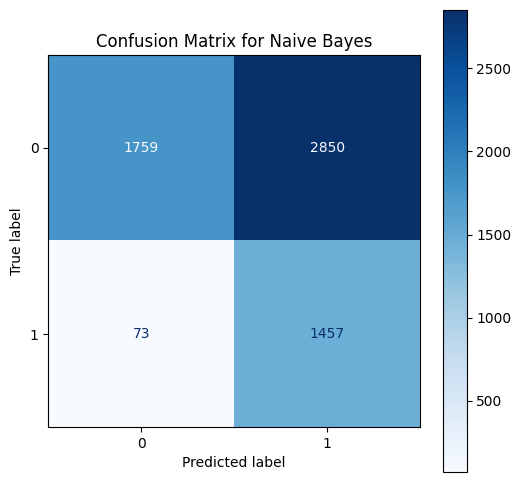

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm_nb = confusion_matrix(y_test, y_pred_nb)
disp_nb = ConfusionMatrixDisplay(confusion_matrix=cm_nb, display_labels=naive_bayes_model.classes_)

fig, ax = plt.subplots(figsize=(6, 6))
disp_nb.plot(cmap=plt.cm.Blues, ax=ax, values_format='d')
plt.title("Confusion Matrix for Naive Bayes")
plt.show()

In [ ]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix



In [ ]:
from sklearn.tree import DecisionTreeClassifier , plot_tree

In [ ]:
model = DecisionTreeClassifier(
    criterion = 'gini',
    max_depth=5,
    min_samples_split=10,
    min_samples_leaf=5,
    min_impurity_decrease=0.01,
    ccp_alpha=0.1,
    random_state=100
)

In [ ]:
from sklearn.metrics import accuracy_score

In [ ]:
model.fit(X_train, y_train)

# Predictions
y_pred_train = model.predict(X_train)
y_pred_test  = model.predict(X_test)

# ================= Metrics =================
Acc_Train = accuracy_score(y_train, y_pred_train)
Acc_Test  = accuracy_score(y_test, y_pred_test)

print(
    Acc_Train,
    Acc_Test,
)

0.7508450417430259 0.7507737416517348


Decision Tree - Plotting the tree


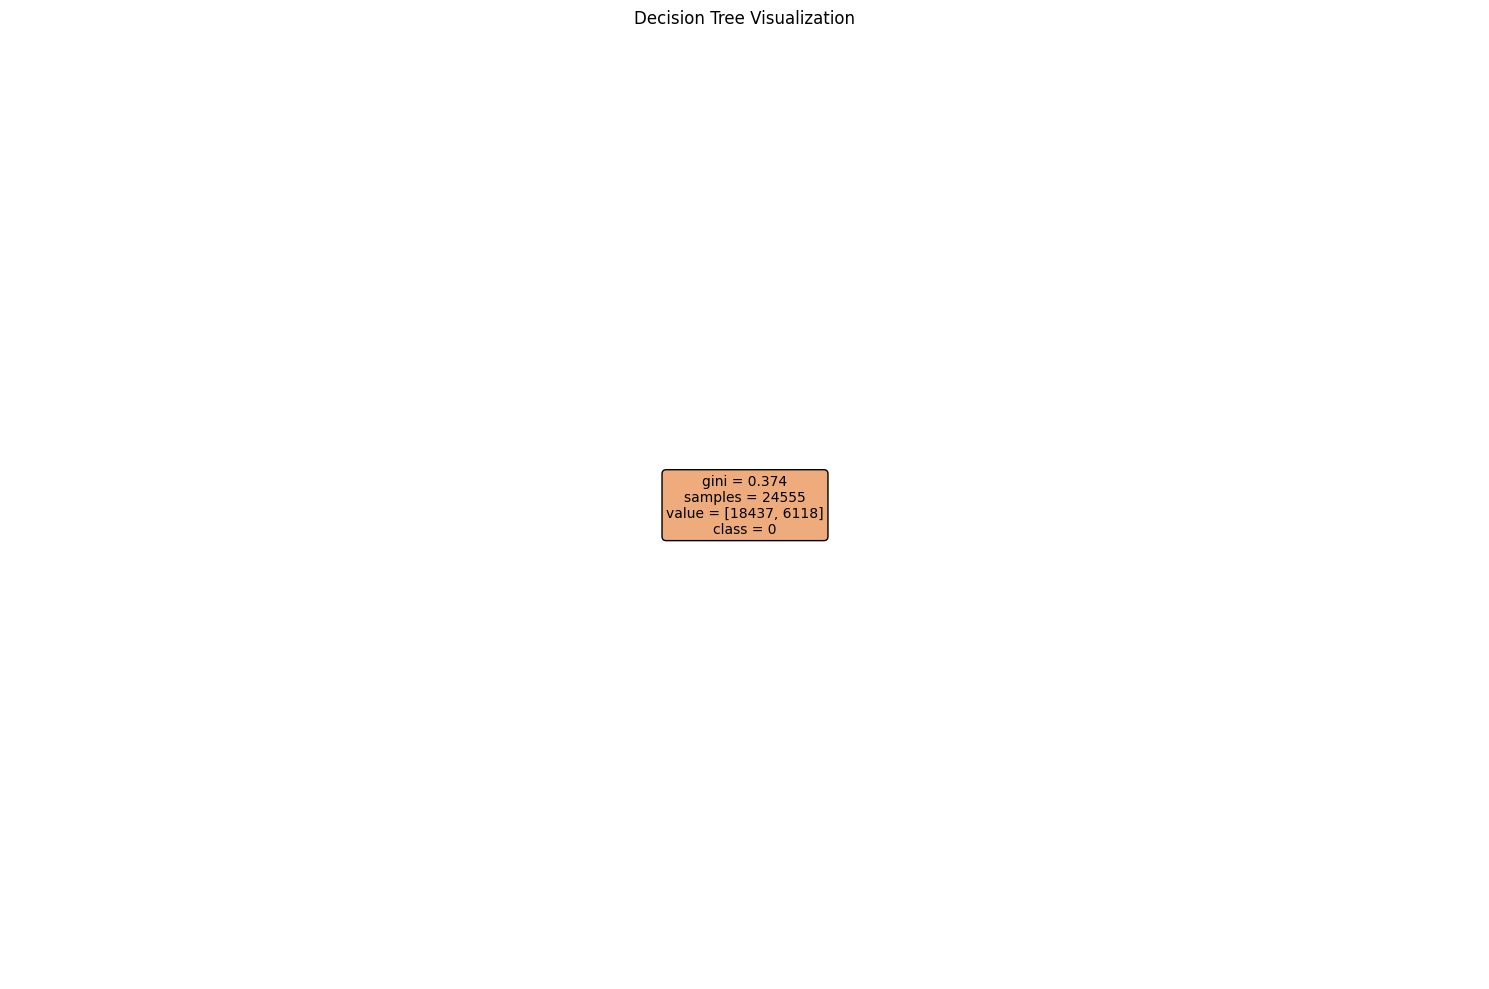

In [ ]:
print("Decision Tree - Plotting the tree")

plt.figure(figsize=(15, 10))
plot_tree(
    model,
    feature_names=X.columns.tolist(),
    class_names=[str(c) for c in model.classes_],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Decision Tree Visualization")
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)

importances = pd.Series(dt.feature_importances_, index=X.columns)
importances = importances.sort_values(ascending=False)

selected_columns = importances.sort_values(ascending=False).index[:5]
print("Decision Tree Selected Features:", selected_columns.tolist())

selected_features = importances.nlargest(5)
print("Decision Tree Feature Scores:", selected_features.tolist())

Decision Tree Selected Features: ['marital.status_Married-civ-spouse', 'fnlwgt', 'education.num', 'age', 'capital.gain']
Decision Tree Feature Scores: [0.2007567853540586, 0.19321631774918696, 0.11497936092729483, 0.11304157094745013, 0.10153043981814017]
